# Characteristic cell histories

Persistent mesh IDs, not conserved fluid parcels. Positions and velocities are in the BH frame; lengths are in $R_\odot$. The grey background is a reproducible random sample of 100,000 archived histories lasting at least one fallback time.

In [1]:
%load_ext autoreload
%autoreload 2
import importlib
import os
import sys
from bisect import bisect_left

sys.path.insert(0, "/zfsstore/user/hey4/rich_tde/dev")

# isort: split
import dev

# isort: split
import h5py
import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

import richio

plt.style.use(dev.path)
REPO_DIR = os.path.abspath(os.path.join(os.path.dirname(dev.__file__), "..", ".."))
TRACK_RUN = "1e4"
TRACK_ENSEMBLE_FILE = os.path.join(
    REPO_DIR,
    "data",
    "processed",
    "ThermodynamicTracks",
    TRACK_RUN,
    "one-tfb",
    "histories.h5",
)
T_LIMITS = (3e3, 1e9)
RHO_LIMITS = (1e-21, 1e2)
ADIABAT_LEVELS = u.unyt_array(np.linspace(1, 9, 50) * 1e9, "erg/(g*K)")
A_RAD = (4 * u.stefan_boltzmann_constant / u.clight).to("erg/(cm**3*K**4)")

In [2]:
sys.path.insert(0, os.path.join(REPO_DIR, "works", "movies"))
from dev.datapaths import TDE_PARAMETERS
from tde_frame import star_orbit_x0

with h5py.File(TRACK_ENSEMBLE_FILE, "r") as archive:
    n_ids = len(archive["ids"])
    catalogue_snapshots = archive["snapshots"][:]
    catalogue_time_code = archive["time_code"][:]
    fallback_time = u.unyt_quantity(
        archive.attrs["fallback_time_code"], richio.units.tscale
    ).to("day")

mbh, mstar, rstar = TDE_PARAMETERS[TRACK_RUN]
frame_offset = u.unyt_array(np.zeros((len(catalogue_snapshots), 3)), "Rsun")
vx_offset = u.unyt_array(np.zeros(len(catalogue_snapshots)), "km/s")
for row in np.flatnonzero(catalogue_snapshots < 21):
    orbit = star_orbit_x0(
        catalogue_time_code[row], m_bh=mbh, m_star=mstar, r_star=rstar, beta=1
    )
    frame_offset[row, :2] = u.unyt_array(orbit[:2], richio.units.lscale)
    vx_offset[row] = u.unyt_quantity(orbit[2], richio.units.get_unit("Vx"))


def read_track(particle_id):
    """Read one archived ID, retaining units and correcting its position to the BH frame."""
    with h5py.File(TRACK_ENSEMBLE_FILE, "r") as archive:
        row = bisect_left(archive["ids"], np.uint64(particle_id))
        assert archive["ids"][row] == particle_id
        start, stop = archive["offsets"][row : row + 2]
        indices = archive["snapshot_index"][start:stop]
        values = archive["values"][start:stop]
    track = {
        "snapshot": catalogue_snapshots[indices],
        "time": u.unyt_array(catalogue_time_code[indices], richio.units.tscale).to(
            "day"
        ),
        "temperature": u.unyt_array(values[:, 1], "K"),
        "star_fraction": values[:, 3],
        "position": u.unyt_array(values[:, 5:8], richio.units.lscale).to("Rsun")
        + frame_offset[indices],
    }
    for key, column, field, unit in (
        ("density", 0, "Density", "g/cm**3"),
        ("dissipation", 2, "Dissipation", "erg/(s*cm**3)"),
        ("pressure", 8, "Pressure", "dyn/cm**2"),
        ("internal_energy", 9, "InternalEnergy", "erg/g"),
    ):
        track[key] = u.unyt_array(values[:, column], richio.units.get_unit(field)).to(
            unit
        )
    track["x"], track["y"], track["z"] = track["position"].T
    track["entropy"] = richio.eos.dp2s(track["density"], track["pressure"])
    return track


print(f"{TRACK_RUN}: {n_ids:,} archived histories; t_fb = {fallback_time:.4f}")

1e4: 15,077,536 archived histories; t_fb = 2.6560 day


A–F retain the six thermodynamic shapes selected from the full archive. G–H add nozzle-catalogue examples: a hot approach and a brief departure. I starts hot and moving outward near the nozzle, then survives another fallback time. These are persistent mesh IDs, not proven material parcels; I does not establish its earlier pericentre crossing. All nine satisfy `Star > 0.999` throughout.

The earlier four examples were IDs 18303, 532382, 2333512679, and 4540152605; the latter two reached the nozzle. The old nozzle catalogue has no history extending $0.1t_\mathrm{fb}$ beyond its last qualifying near point. G–I show what the saved histories resolve without joining different IDs.

In [3]:
EXAMPLES = [
    ("A: Dense cooling", 536923),
    ("B: Dilute cooling", 1386935),
    ("C: Warm branch", 341196),
    ("D: Second heating", 344786),
    ("E: Dense reheating", 790847),
    ("F: Hot cooling loop", 12226912164),
    ("G: Hot nozzle approach", 1329589568),
    ("H: Brief nozzle departure", 110815),
    ("I: Hot outward start", 13493071075),
]
TRACK_LABELS, TRACK_IDS = zip(*EXAMPLES)
tracks = [read_track(particle_id) for particle_id in TRACK_IDS]
track_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"][: len(tracks)]
for label, particle_id, track in zip(TRACK_LABELS, TRACK_IDS, tracks):
    assert np.all(track["star_fraction"] > 0.999)
    time = (track["time"] / fallback_time).to_value("dimensionless")
    print(
        f"{label}: ID {particle_id}, {len(time)} points, t/t_fb = {time[0]:.3f}–{time[-1]:.3f}"
    )

A: Dense cooling: ID 536923, 152 points, t/t_fb = -0.008–2.175
B: Dilute cooling: ID 1386935, 152 points, t/t_fb = -0.008–2.175
C: Warm branch: ID 341196, 152 points, t/t_fb = -0.008–2.175
D: Second heating: ID 344786, 152 points, t/t_fb = -0.008–2.175
E: Dense reheating: ID 790847, 152 points, t/t_fb = -0.008–2.175
F: Hot cooling loop: ID 12226912164, 65 points, t/t_fb = 1.047–2.063
G: Hot nozzle approach: ID 1329589568, 104 points, t/t_fb = 0.219–2.032
H: Brief nozzle departure: ID 110815, 147 points, t/t_fb = -0.008–2.095
I: Hot outward start: ID 13493071075, 67 points, t/t_fb = 1.126–2.175


In [23]:
# Saved snapshots of observed turns, in the same order as EXAMPLES.
TURN_SNAPSHOTS = [
    [124],  # A: shallow temperature minimum
    [43, 49],  # B: temperature minimum and reheating peak
    [78, 89],  # C: temperature minimum and reheating peak
    [83, 100, 143],  # D: first heating turn, peak, onset of second heating
    [127],  # E: temperature minimum before dense reheating
    [108, 130, 142],  # F: cooling minimum, compression peak, second minimum
    [107, 133, 141],  # G: cooling minimum, approach, last pre-end nozzle sample
    [90, 140],  # H: cooling minimum, closest late approach
    [118, 139],  # I: cooling minimum, density peak on return
]
# Offsets in points: start, turns, end.
LABEL_OFFSETS = [
    [(-8, 4), (8, 36), (8, 4)],
    [(-8, 4), (8, 16), (8, -8), (8, 4)],
    [(-8, 4), (8, 12), (8, 6), (8, 4)],
    [(-8, 4), (8, 28), (8, 16), (-8, -8), (75, 4)],
    [(-8, 4), (8, -6), (8, 4)],
    [(-8, 4), (-6, -6), (-6, 8), (-6, -6), (8, -6)],
    [(8, 4), (8, -6), (4, 4), (4, 4), (-8, 12)],
    [(-8, 4), (8, -6), (8, 4), (8, 6)],
    [(8, 4), (4, -4), (4, 4), (8, 8)],
]
for index, (track, snapshots) in enumerate(zip(tracks, TURN_SNAPSHOTS)):
    turns = np.searchsorted(track["snapshot"], snapshots)
    assert np.array_equal(track["snapshot"][turns], snapshots)
    track["point_rows"] = np.r_[0, turns, len(track["snapshot"]) - 1]
    # Keep B4 as the endpoint name after removing the nearby B3 checkpoint.
    numbers = [0, 1, 2, 4] if index == 1 else range(len(track["point_rows"]))
    track["point_names"] = [f"{chr(65 + index)}{number}" for number in numbers]


def mark_points(ax, track, x, y):
    """Mark the same named samples in the time and orbital plots."""
    for number, (row, name) in enumerate(
        zip(track["point_rows"], track["point_names"])
    ):
        offset = (4, 5)
        if number == 0:
            offset = (4, 4)
            if name in ("B0", "E0"):
                offset = (18, 4)
            elif name == "C0":
                offset = (32, 4)
        elif number == len(track["point_rows"]) - 1:
            offset = (-4, -10)
        if name in ("A2", "C3", "E2", "G4"):
            offset = (4, 4)
        if name in ("G2", "I2"):
            offset = (4, 12)
        offset = {"G3": (-8, 5), "G4": (8, 4), "H2": (-8, -14)}.get(name, offset)
        ax.plot(
            x[row],
            y[row],
            "o",
            color="black",
            mfc="white" if number == 0 else "black",
            ms=3,
        )
        ax.annotate(
            name,
            (x[row], y[row]),
            xytext=offset,
            textcoords="offset points",
            fontsize="x-small",
            ha="left" if offset[0] > 0 else "right",
            va="bottom" if offset[1] > 0 else "top",
        )

## Thermodynamic tracks

Grey: 100,000 archived histories sampled uniformly without replacement, using a fixed random seed. Rerun the plotting cells below to adjust the figures. Thin contours are EOS adiabats; the dashed curve is $P_\mathrm{gas}=aT^4/3$. Open circles mark starts and filled circles mark ends.

Named points (A0, A1, …) match the time series and orbital plots. Each phase label also gives $t/t_\mathrm{fb}$ and $(X,Y,Z)$ in $R_\odot$. Turns are observed bends at saved times, not inferred shock times. Labels have no connectors.

In [5]:
T_grid = u.unyt_array(np.geomspace(*T_LIMITS, 250), "K")
rho_grid = u.unyt_array(np.geomspace(*RHO_LIMITS, 250), "g/cm**3")
P_grid = richio.eos.dT2p(rho_grid[:, None], T_grid[None, :])
s_grid = richio.eos.dp2s(rho_grid[:, None], P_grid)
pressure_ratio = (P_grid / (A_RAD * T_grid[None, :] ** 4 / 3)).to_value("dimensionless")

In [20]:
# Draw a reproducible random sample of archived histories.
from matplotlib.backends.backend_agg import FigureCanvasAgg

BACKGROUND_COUNT = 100_000
BACKGROUND_SEED = 20261005
background_rows = np.sort(
    np.random.default_rng(BACKGROUND_SEED).choice(
        n_ids, BACKGROUND_COUNT, replace=False
    )
)
paths = []
with h5py.File(TRACK_ENSEMBLE_FILE, "r") as archive:
    offsets = archive["offsets"]
    source = archive["values"]
    for row in background_rows:
        start, stop = offsets[row : row + 2]
        values = source[start:stop, :2]
        density = u.unyt_array(values[:, 0], richio.units.get_unit("Density")).to(
            "g/cm**3"
        )
        temperature = u.unyt_array(values[:, 1], "K")
        # The raster uses numeric log coordinates with mixed physical units.
        vertices = np.column_stack(
            (temperature.to_value("K"), density.to_value("g/cm**3"))
        )
        paths.append(np.log10(vertices))

background_fig = plt.figure(figsize=(6, 5), dpi=180)
background_ax = background_fig.add_axes([0, 0, 1, 1])
background_ax.set(xlim=np.log10(T_LIMITS), ylim=np.log10(RHO_LIMITS))
background_ax.set_axis_off()
canvas = FigureCanvasAgg(background_fig)
canvas.draw()
lines = LineCollection(paths, colors="0.65", linewidths=0.2, alpha=0.03)
background_ax.add_collection(lines, autolim=False)
background_ax.draw_artist(lines)
background = np.asarray(canvas.buffer_rgba()).copy()
plt.close(background_fig)
print(f"Background: {len(paths):,} random histories; seed {BACKGROUND_SEED}.")

Background: 100,000 random histories; seed 20261005.


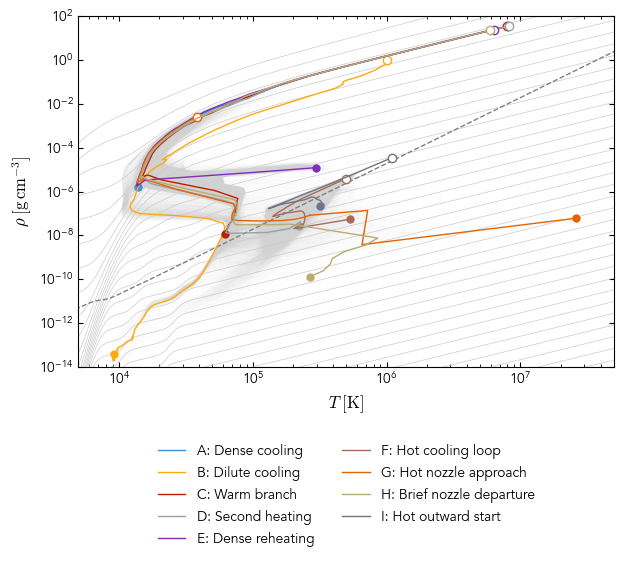

In [28]:
# Display limits retain all nine example tracks.
tlim = (5e3, 5e7)
rlim = (1e-14, 1e2)
# Keep the background registered to its original logarithmic domain.
extent = np.r_[
    (np.log10(T_LIMITS) - np.log10(tlim[0])) / np.log10(tlim[1] / tlim[0]),
    (np.log10(RHO_LIMITS) - np.log10(rlim[0])) / np.log10(rlim[1] / rlim[0]),
]
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.imshow(background, extent=extent, transform=ax.transAxes, aspect="auto", alpha=0.5)
adiabats = ax.contour(
    T_grid,
    rho_grid,
    s_grid.to_value("erg/(g*K)"),
    levels=ADIABAT_LEVELS,
    colors="0.8",
    linewidths=0.5,
)
ax.contour(T_grid, rho_grid, pressure_ratio, levels=[1], colors="0.5", linestyles="--")
for label, track, color in zip(TRACK_LABELS, tracks, track_colors):
    ax.plot(track["temperature"], track["density"], color=color, label=label)
    ax.plot(
        track["temperature"][0],
        track["density"][0],
        "o",
        color=color,
        mfc="white",
        mec=color,
        mew=1,
    )
    ax.plot(track["temperature"][-1], track["density"][-1], "o", color=color)
ax.set(
    xscale="log",
    yscale="log",
    xlim=tlim,
    ylim=rlim,
    xlabel=r"$T\;[\mathrm{K}]$",
    ylabel=r"$\rho\;[\mathrm{g\,cm^{-3}}]$",
)
ax.legend(fontsize="small", ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
plt.show()

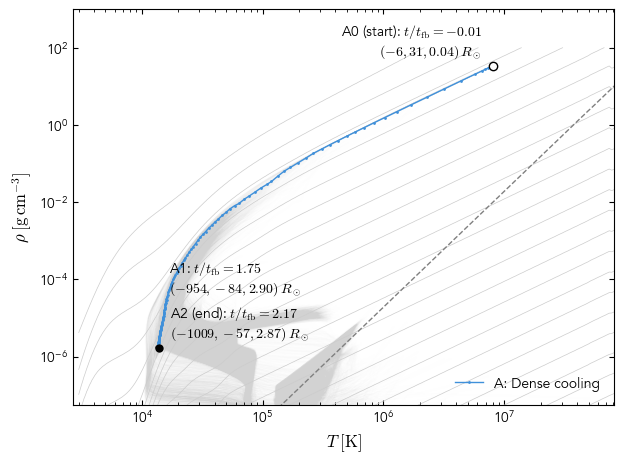

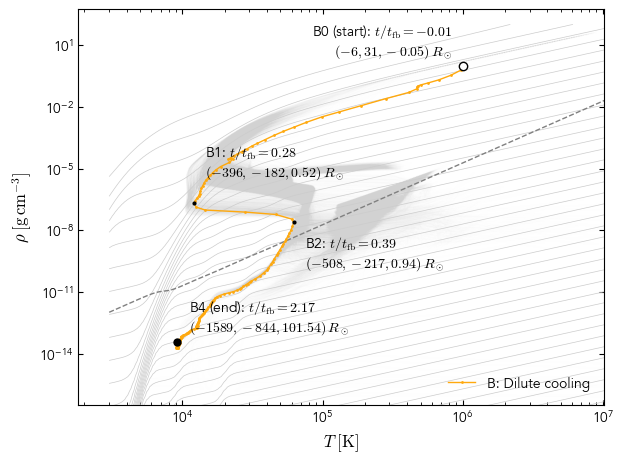

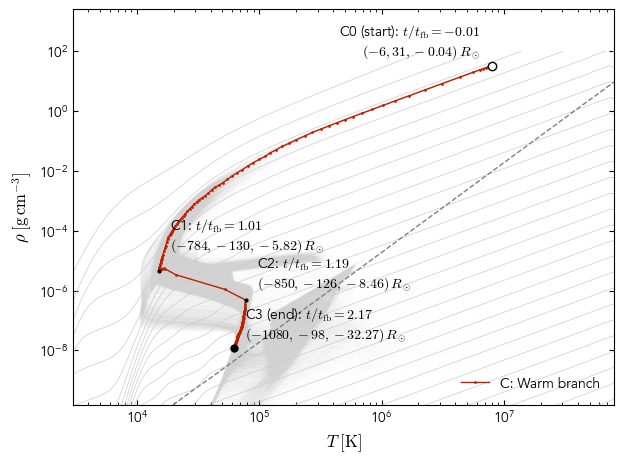

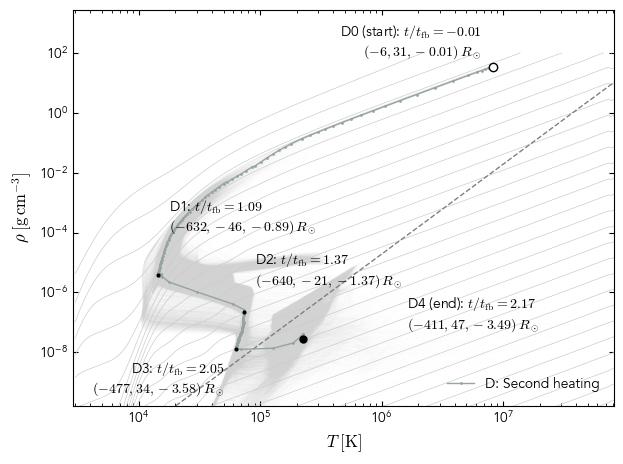

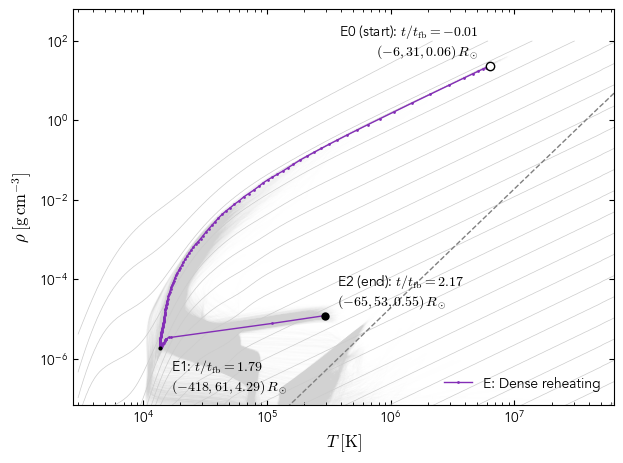

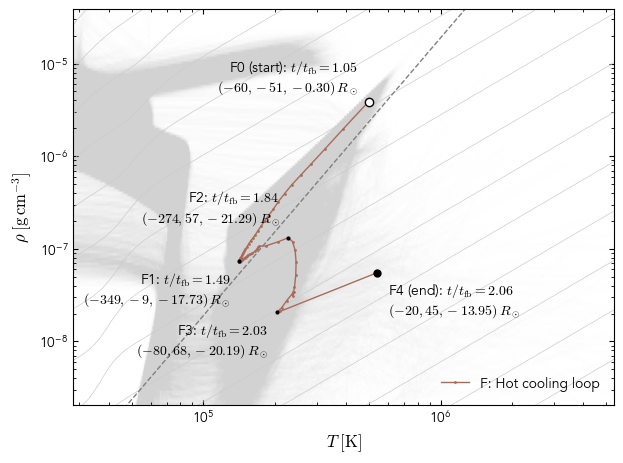

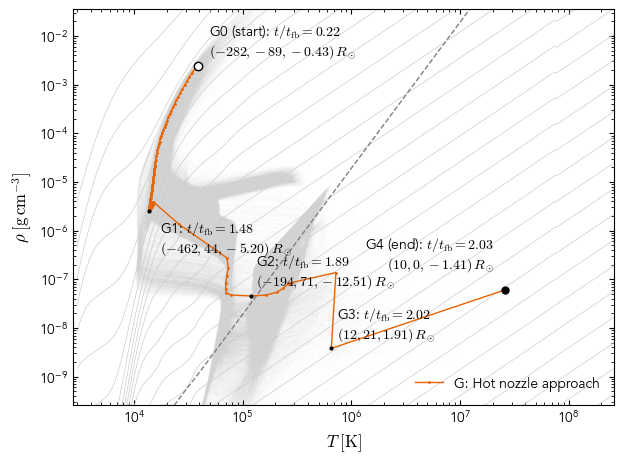

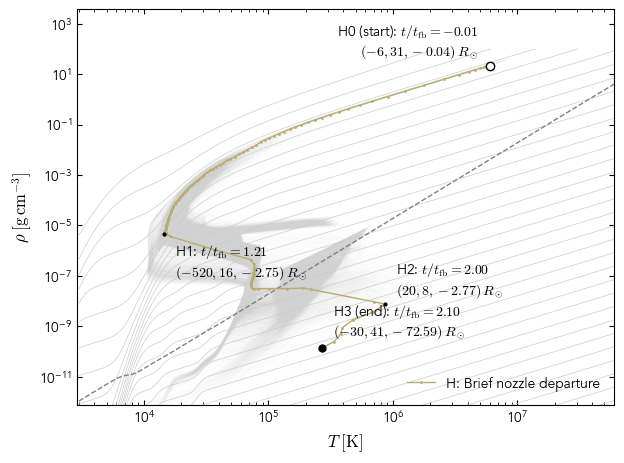

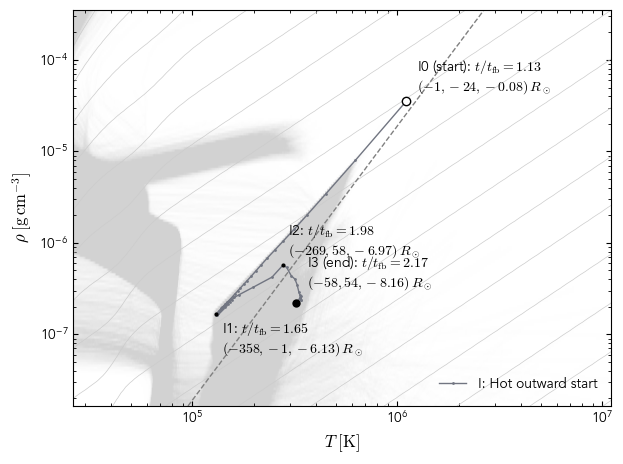

In [24]:
# Labels give t/t_fb and the BH-frame (X, Y, Z) in Rsun at saved snapshots.
for label, track, color, snapshots, offsets in zip(
    TRACK_LABELS, tracks, track_colors, TURN_SNAPSHOTS, LABEL_OFFSETS
):
    fig, ax = plt.subplots()
    # Fit this history, mapping the existing log-coordinate background to the new limits.
    # Numeric limits register the raster; physical lines below retain their units.
    T_values = track["temperature"].to_value("K")
    rho_values = track["density"].to_value("g/cm**3")
    tlim = (T_values.min() / 5, T_values.max() * 10)
    rho_margin = max(10, (rho_values.max() / rho_values.min()) ** 0.2)
    rlim = (rho_values.min() / rho_margin, rho_values.max() * rho_margin)
    extent = np.r_[
        (np.log10(T_LIMITS) - np.log10(tlim[0])) / np.log10(tlim[1] / tlim[0]),
        (np.log10(RHO_LIMITS) - np.log10(rlim[0])) / np.log10(rlim[1] / rlim[0]),
    ]
    ax.imshow(
        background,
        extent=extent,
        transform=ax.transAxes,
        aspect="auto",
        alpha=0.5,
    )
    ax.contour(
        T_grid,
        rho_grid,
        s_grid.to_value("erg/(g*K)"),
        levels=ADIABAT_LEVELS,
        colors="0.8",
        linewidths=0.5,
    )
    ax.contour(
        T_grid, rho_grid, pressure_ratio, levels=[1], colors="0.5", linestyles="--"
    )
    ax.plot(
        track["temperature"], track["density"], "o-", ms=2, color=color, label=label
    )
    ax.plot(
        track["temperature"][0],
        track["density"][0],
        "o",
        color="black",
        mfc="white",
        mec="black",
        mew=1,
    )
    ax.plot(track["temperature"][-1], track["density"][-1], "o", color="black")
    kinds = ["Start", *[""] * len(snapshots), "End"]
    for row, name, kind, (dx, dy) in zip(
        track["point_rows"], track["point_names"], kinds, offsets
    ):
        time = (track["time"][row] / fallback_time).to_value("dimensionless")
        x, y, z = track["position"][row].to_value("Rsun")
        prefix = f"{name} ({kind.lower()}): " if kind else f"{name}: "
        text = (
            prefix
            + f"$t/t_{{\\rm fb}}={time:.2f}$\n"
            + f"$({x:.0f}, {y:.0f}, {z:.2f})\\,R_\\odot$"
        )
        point = (track["temperature"][row], track["density"][row])
        if not kind:
            ax.plot(*point, "o", color="black", ms=3)
        ax.annotate(
            text,
            point,
            xytext=(dx, dy),
            textcoords="offset points",
            color="black",
            fontsize="small",
            ha="left" if dx >= 0 else "right",
            va="bottom" if dy >= 0 else "top",
        )
    ax.set(
        xscale="log",
        yscale="log",
        xlim=tlim,
        ylim=rlim,
        xlabel=r"$T\;[\mathrm{K}]$",
        ylabel=r"$\rho\;[\mathrm{g\,cm^{-3}}]$",
    )
    ax.legend(loc="lower right", fontsize="small")
    fig.tight_layout()
    plt.show()

## Time histories

Run setup, the reader, selection, and named-point cell before this section; the background is not required. Three tracks per panel keep the point labels readable. Names mark the gas curves in the energy and temperature plots.

$s$ is gas specific entropy from the EOS. $e_\mathrm{rad}$ is specific energy, so $T_\mathrm{rad}=(\rho e_\mathrm{rad}/a)^{1/4}$ and $m_\mathrm{cell}=\rho V$. The x(t) style uses stored BH-frame velocity. Each continuous velocity-sign interval is drawn as one line, so the negative-velocity dashes remain visible.

In [13]:
# Match only the selected IDs: these three fields are absent from the track archive.
from concurrent.futures import ProcessPoolExecutor

sys.path.insert(0, os.path.join(REPO_DIR, "works", "shock-tde"))
cell_history = importlib.import_module("trace-cell-histories")
for track in tracks:
    for key, field in (
        ("radiation_energy", "Erad"),
        ("volume", "Volume"),
        ("vx", "Vx"),
    ):
        track[key] = u.unyt_array(
            np.full(len(track["snapshot"]), np.nan), richio.units.get_unit(field)
        )

with ProcessPoolExecutor(max_workers=4) as pool:
    for path_index, path in enumerate(dev.DATAPATHS(TRACK_RUN)):
        snapnum = int(os.path.basename(path).rsplit("_", 1)[-1].split(".")[0])
        selected = {
            particle_id: (track, int(np.searchsorted(track["snapshot"], snapnum)))
            for particle_id, track in zip(TRACK_IDS, tracks)
            if snapnum in track["snapshot"]
        }
        if not selected:
            continue
        targets = np.array(sorted(selected), dtype=np.uint64)
        with h5py.File(path, "r") as source:
            ranks = [name for name in source if name.startswith("rank")]
        found = set()
        for _, (ids, values) in cell_history._rank_results(
            path, ranks, targets, pool, 4, fields=("Erad", "Volume", "Vx")
        ):
            for particle_id, values_row in zip(ids, values):
                track, row = selected[int(particle_id)]
                for key, value in zip(("radiation_energy", "volume", "vx"), values_row):
                    track[key][row] = u.unyt_quantity(value, track[key].units)
                found.add(int(particle_id))
            if len(found) == len(targets):
                break
        assert found == set(selected), f"Missing selected IDs in snapshot {snapnum}"
        if (path_index + 1) % 25 == 0 or snapnum == catalogue_snapshots[-1]:
            print(f"Read extra fields through snapshot {snapnum}", flush=True)

for track in tracks:
    indices = np.searchsorted(catalogue_snapshots, track["snapshot"])
    track["radiation_energy"] = track["radiation_energy"].to("erg/g")
    track["vx"] = track["vx"].to("km/s") + vx_offset[indices]
    track["mass"] = (track["density"] * track["volume"]).to("Msun")
    # Erad is specific radiation energy; rho * Erad is energy per volume.
    track["radiation_temperature"] = (
        track["density"] * track["radiation_energy"] / A_RAD
    ) ** 0.25

Read extra fields through snapshot 24


Read extra fields through snapshot 49


Read extra fields through snapshot 74


Read extra fields through snapshot 99


Read extra fields through snapshot 124


Read extra fields through snapshot 149


Read extra fields through snapshot 151


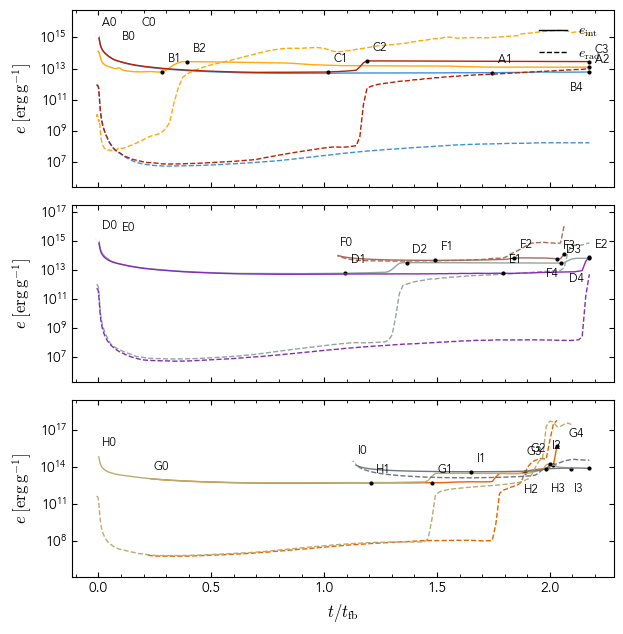

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        values = track["internal_energy"]
        ax.plot(time, values, color=color, label=TRACK_LABELS[index].split(":")[0])
        ax.plot(time, track["radiation_energy"], "--", color=color)
        mark_points(ax, track, time, values)
    ax.set(ylabel=r"$e\;[\mathrm{erg\,g^{-1}}]$", yscale="log")
    ax.margins(y=0.15)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
axes[0].legend(
    handles=[
        Line2D([], [], color="k", label=r"$e_\mathrm{int}$"),
        Line2D([], [], color="k", linestyle="--", label=r"$e_\mathrm{rad}$"),
    ],
    loc="upper right",
    fontsize="small",
)
fig.tight_layout()
plt.show()

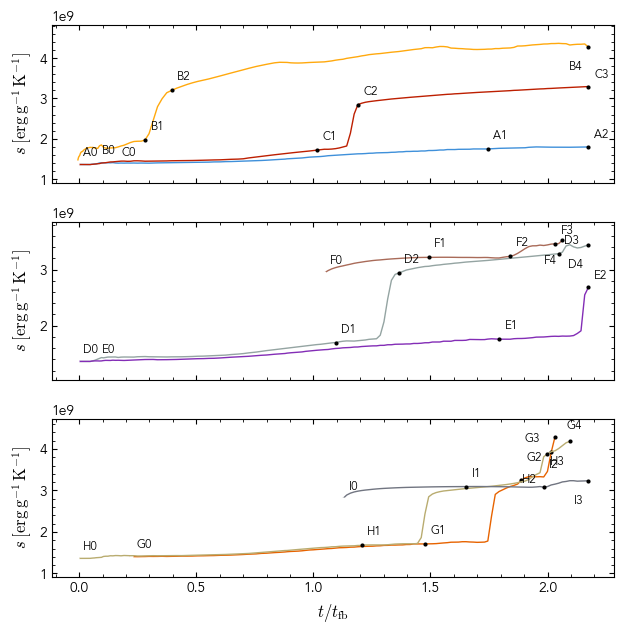

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        values = track["entropy"]
        ax.plot(time, values, color=color, label=TRACK_LABELS[index].split(":")[0])
        mark_points(ax, track, time, values)
    ax.set(ylabel=r"$s\;[\mathrm{erg\,g^{-1}\,K^{-1}}]$", yscale="linear")
    ax.margins(y=0.15)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
fig.tight_layout()
plt.show()

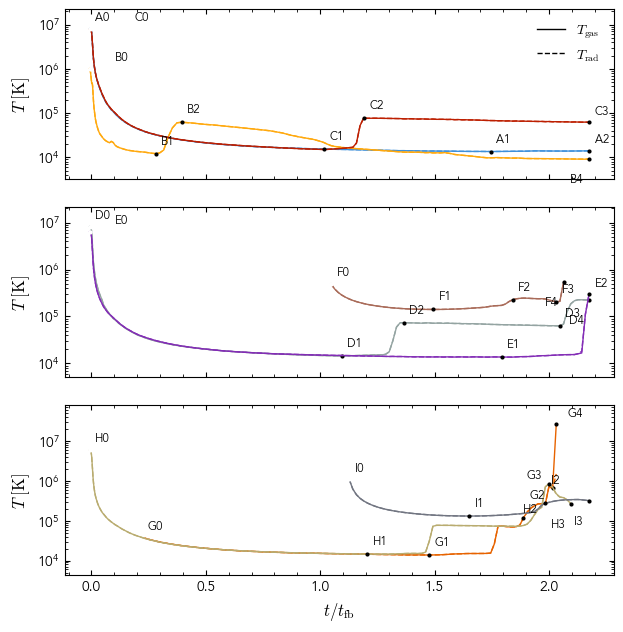

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        values = track["temperature"]
        ax.plot(time, values, color=color, label=TRACK_LABELS[index].split(":")[0])
        ax.plot(time, track["radiation_temperature"], "--", color=color)
        mark_points(ax, track, time, values)
    ax.set(ylabel=r"$T\;[\mathrm{K}]$", yscale="log")
    ax.margins(y=0.15)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
axes[0].legend(
    handles=[
        Line2D([], [], color="k", label=r"$T_\mathrm{gas}$"),
        Line2D([], [], color="k", linestyle="--", label=r"$T_\mathrm{rad}$"),
    ],
    loc="upper right",
    fontsize="small",
)
fig.tight_layout()
plt.show()

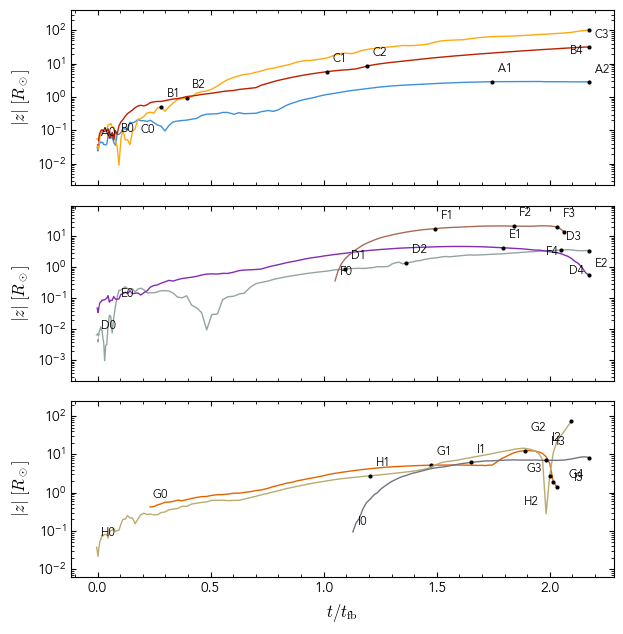

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        values = abs(track["z"])
        ax.plot(time, values, color=color, label=TRACK_LABELS[index].split(":")[0])
        mark_points(ax, track, time, values)
    ax.set(ylabel=r"$|z|\;[R_\odot]$", yscale="log")
    ax.margins(y=0.15)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
fig.tight_layout()
plt.show()

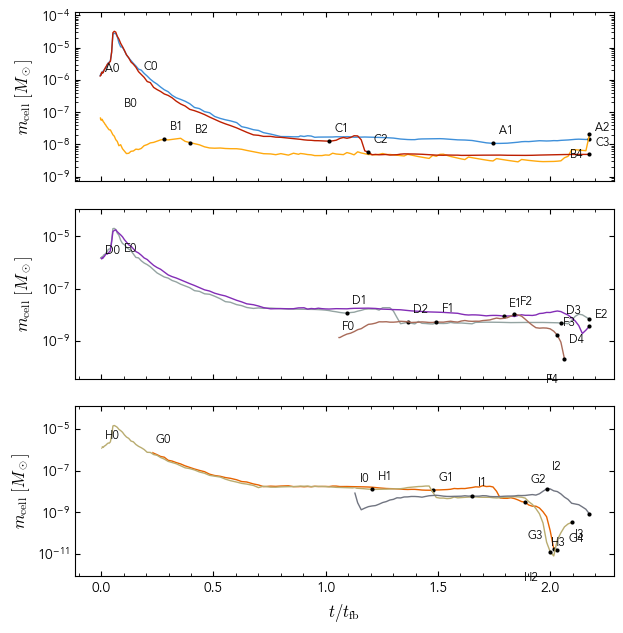

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        values = track["mass"]
        ax.plot(time, values, color=color, label=TRACK_LABELS[index].split(":")[0])
        mark_points(ax, track, time, values)
    ax.set(ylabel=r"$m_\mathrm{cell}\;[M_\odot]$", yscale="log")
    ax.margins(y=0.15)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
fig.tight_layout()
plt.show()

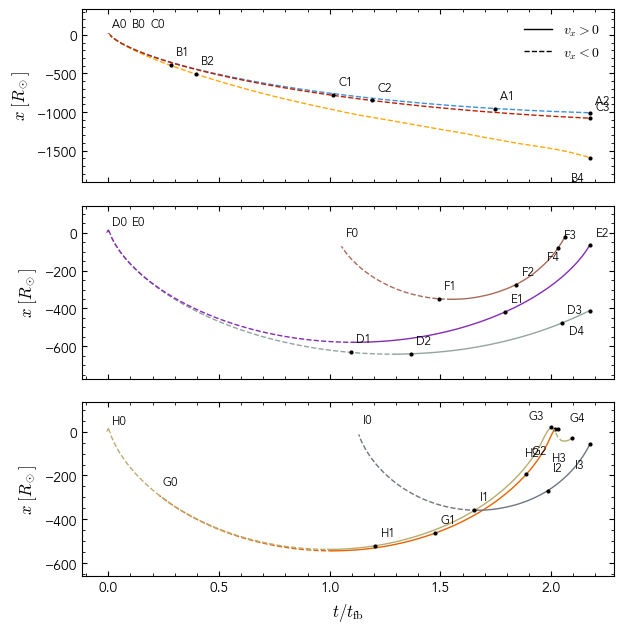

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(6.4, 6.5), sharex=True)
for group, ax in enumerate(axes):
    for index in range(3 * group, 3 * group + 3):
        track, color = tracks[index], track_colors[index]
        time = track["time"] / fallback_time
        vx = track["vx"]
        # Split sign-changing intervals at the linearly interpolated zero of stored vx.
        crossings = np.flatnonzero(vx[:-1] * vx[1:] < 0)
        fraction = -vx[crossings] / (vx[crossings + 1] - vx[crossings])
        tcross = time[crossings] + fraction * (time[crossings + 1] - time[crossings])
        xcross = track["x"][crossings] + fraction * (
            track["x"][crossings + 1] - track["x"][crossings]
        )
        tplot = np.insert(time, crossings + 1, tcross)
        xplot = np.insert(track["x"], crossings + 1, xcross)
        vplot = np.insert(vx, crossings + 1, 0)
        styles = np.where(vplot[:-1] + vplot[1:] >= 0, "solid", "dashed")
        boundaries = np.r_[
            0, np.flatnonzero(styles[1:] != styles[:-1]) + 1, len(styles)
        ]
        # One path per sign interval preserves the dash phase across saved samples.
        for start, stop in zip(boundaries[:-1], boundaries[1:]):
            ax.plot(
                tplot[start : stop + 1],
                xplot[start : stop + 1],
                color=color,
                linestyle=styles[start],
            )
        mark_points(ax, track, time, track["x"])
    ax.set_ylabel(r"$x\;[R_\odot]$")
    ax.margins(y=0.2)
axes[-1].set_xlabel(r"$t/t_\mathrm{fb}$")
axes[0].legend(
    handles=[
        Line2D([], [], color="k", label=r"$v_x>0$"),
        Line2D([], [], color="k", linestyle="--", label=r"$v_x<0$"),
    ],
    loc="upper right",
    fontsize="small",
)
fig.tight_layout()
plt.show()

Point names within 3 r_p are shown in the nozzle zoom; dotted circle: r_p.
A0–E0 and H0 belong to the initial encounter; G3, G4, H2, I0 are later near-nozzle samples.


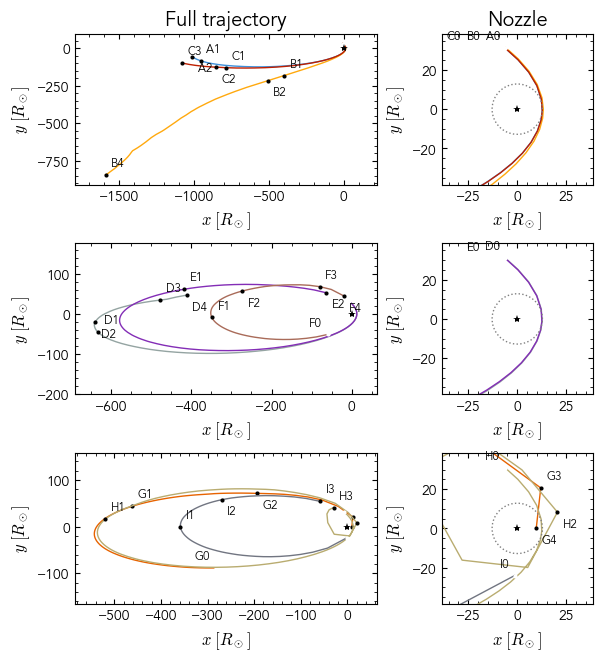

In [15]:
# Full orbit and nozzle zoom for the same three groups and named samples.
rp = u.unyt_quantity(rstar * (mbh / mstar) ** (1 / 3), richio.units.lscale).to("Rsun")
fig, axes = plt.subplots(
    3, 2, figsize=(7, 6.5), layout="compressed", gridspec_kw={"width_ratios": [2, 1]}
)
for group, (full, nozzle) in enumerate(axes):
    chosen = range(3 * group, 3 * group + 3)
    for index in chosen:
        track, color = tracks[index], track_colors[index]
        for ax in (full, nozzle):
            ax.plot(
                track["x"],
                track["y"],
                color=color,
                label=TRACK_LABELS[index].split(":")[0],
            )
            radius = np.sqrt((track["position"] ** 2).sum(axis=1))
            for number, (row, name) in enumerate(
                zip(track["point_rows"], track["point_names"])
            ):
                ax.plot(
                    track["x"][row],
                    track["y"][row],
                    "o",
                    color="black",
                    mfc="white" if number == 0 else "black",
                    ms=3,
                )
                # The zoom carries labels near the BH, where the full view is crowded.
                if ax is full and radius[row] < 3 * rp:
                    continue
                offset = (4, 4 if number % 2 else -4)
                if number == 0:
                    offset = (-4, 4)
                    if name in ("B0", "E0"):
                        offset = (-18, 4)
                    elif name == "C0":
                        offset = (-32, 4)
                if name == "B4":
                    offset = (4, 4)
                ax.annotate(
                    name,
                    (track["x"][row], track["y"][row]),
                    xytext=offset,
                    textcoords="offset points",
                    fontsize="x-small",
                    ha="left" if offset[0] > 0 else "right",
                    va="bottom" if offset[1] > 0 else "top",
                )
    x = np.concatenate([tracks[i]["x"] for i in chosen])
    y = np.concatenate([tracks[i]["y"] for i in chosen])
    width = 1.15 * max(np.ptp(x), 2 * np.ptp(y))
    xc, yc = (x.min() + x.max()) / 2, (y.min() + y.max()) / 2
    full.set(
        xlim=(xc - width / 2, xc + width / 2), ylim=(yc - width / 4, yc + width / 4)
    )
    nozzle.set(xlim=(-3 * rp, 3 * rp), ylim=(-3 * rp, 3 * rp))
    angle = np.linspace(0, 2 * np.pi, 200)
    nozzle.plot(rp * np.cos(angle), rp * np.sin(angle), ":", color="0.5")
    for ax in (full, nozzle):
        ax.plot(0, 0, "*", color="black")
        ax.set(xlabel=r"$x\;[R_\odot]$", ylabel=r"$y\;[R_\odot]$", aspect="equal")
axes[0, 0].set_title("Full trajectory")
axes[0, 1].set_title("Nozzle")
print("Point names within 3 r_p are shown in the nozzle zoom; dotted circle: r_p.")
print(
    "A0–E0 and H0 belong to the initial encounter; G3, G4, H2, I0 are later near-nozzle samples."
)
plt.show()